---

Name : Abhijeet Parmar      
Enrollment No.: 23SOECE11065  
Div.: CE-B    
Roll No.: 22    

---

# <b>Tutorial 3 - Convolutional Neural Networks
</b>

---
### <b>Practical 1: Implementation of Convolutional Neural Network (CNN) for Image Classification
</b>

**Definition:** Implement a Convolutional Neural Network (CNN) using Python and TensorFlow/Keras to classify images into different categories. Experiment with convolution layers, filters, padding, stride, max pooling, and average pooling to understand feature extraction and image classification.


---

### Dataset Loading and Preprocessing

Load the MNIST dataset and preprocess the images for CNN model training.

In [2]:
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt

# Load MNIST dataset
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

# Normalize pixel values
X_train = X_train / 255.0
X_test = X_test / 255.0

# Add dimension
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (60000, 28, 28, 1)
Testing Data: (10000, 28, 28, 1)


### Display Sample Images

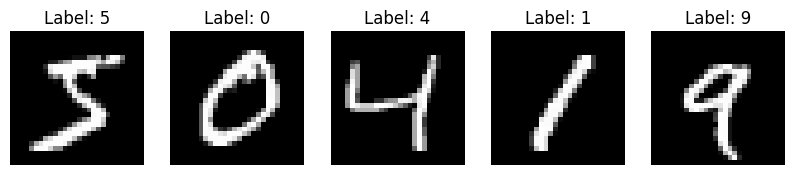

In [3]:
plt.figure(figsize=(10, 4))

for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap='gray')
    plt.title("Label: " + str(y_train[i]))
    plt.axis('off')

plt.show()

In [4]:
# Create CNN model
model = keras.Sequential([

    # First convolution layer
    keras.layers.Conv2D(
        32,
        kernel_size=(3, 3),
        strides=(1, 1),
        padding='same',
        activation='relu',
        input_shape=(28, 28, 1)
    ),

    # Max pooling layer
    keras.layers.MaxPooling2D(pool_size=(2, 2)),

    # Second convolution layer
    keras.layers.Conv2D(
        64,
        kernel_size=(3, 3),
        padding='same',
        activation='relu'
    ),

    # Average pooling layer
    keras.layers.AveragePooling2D(pool_size=(2, 2)),

    # Flatten layer
    keras.layers.Flatten(),

    # Fully connected layer
    keras.layers.Dense(128, activation='relu'),

    # Output layer with 10 classes
    keras.layers.Dense(10, activation='softmax')
])

# Display model architecture
model.summary()

C:\Users\abhij\AppData\Roaming\Python\Python314\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 7, 7, 64)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# Compile the CNN model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the CNN model
history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.9392 - loss: 0.2027 - val_accuracy: 0.9847 - val_loss: 0.0574
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9833 - loss: 0.0557 - val_accuracy: 0.9877 - val_loss: 0.0441
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9889 - loss: 0.0377 - val_accuracy: 0.9867 - val_loss: 0.0447
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9914 - loss: 0.0279 - val_accuracy: 0.9862 - val_loss: 0.0480
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9939 - loss: 0.0215 - val_accuracy: 0.9852 - val_loss: 0.0546


In [6]:
# Evaluate the CNN model
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9839 - loss: 0.0500
Test Loss: 0.05
Test Accuracy: 98.39 %


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step


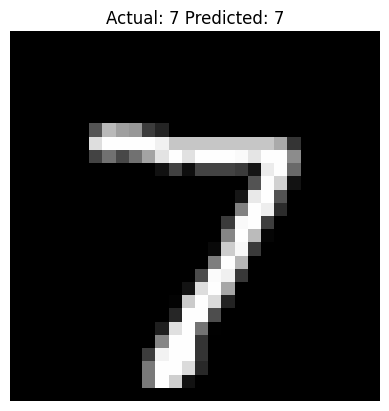

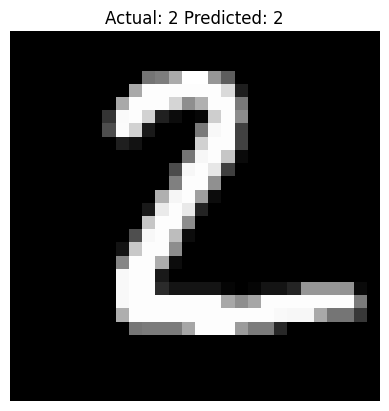

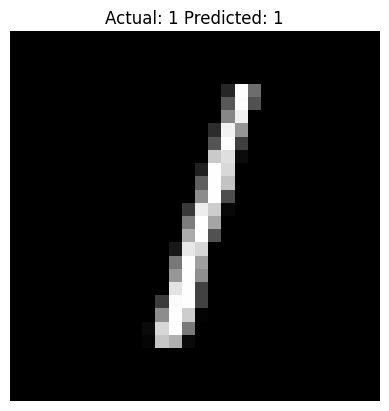

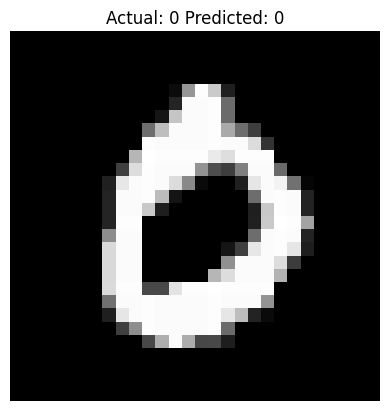

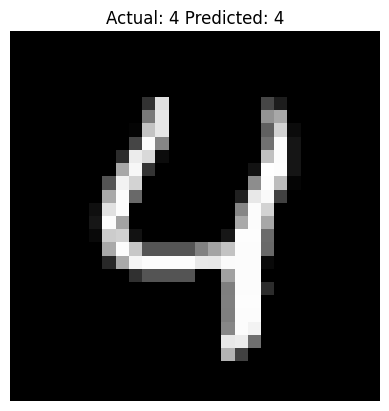

In [7]:
# Predict test images
predictions = model.predict(X_test[:5])

# Display actual and predicted labels
for i in range(5):

    predicted_label = np.argmax(predictions[i])

    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')
    plt.title(
        "Actual: " + str(y_test[i]) +
        " Predicted: " + str(predicted_label)
    )
    plt.axis('off')
    plt.show()

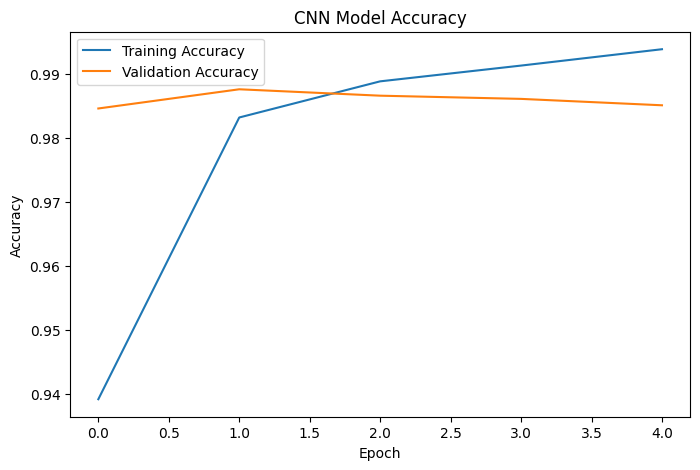

In [8]:
# Plot training and validation accuracy
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('CNN Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

---
### <b>Practical 2: Object Detection Using YOLO
</b>

**Definition:** Implement an object detection system using the YOLO (You Only Look Once) algorithm with Python and OpenCV to identify and locate multiple objects in images or real-time video using bounding boxes and class labels.


---

In [9]:
# Install required libraries
%pip install ultralytics opencv-python

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
# Import required libraries
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

In [14]:
# Load pre-trained YOLO model
model = YOLO('yolov8n.pt')

print("YOLO Model Loaded Successfully")

YOLO Model Loaded Successfully


Webcam Image Captured Successfully


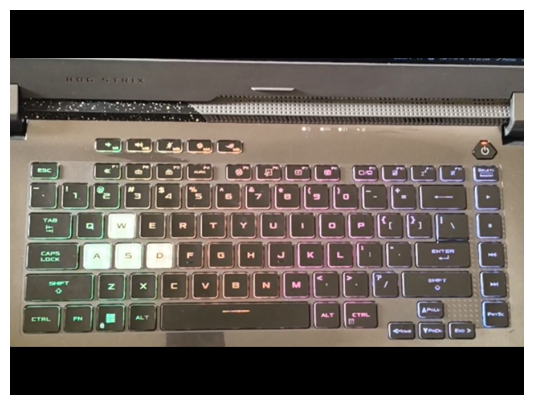

In [17]:
# Open webcam
cap = cv2.VideoCapture(0)

# Capture one frame
ret, frame = cap.read()

# Release webcam
cap.release()

# Check webcam
if ret:
    print("Webcam Image Captured Successfully")

    # Display captured image
    plt.figure(figsize=(8, 5))
    plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.show()
else:
    print("Unable to access webcam")


0: 480x640 1 keyboard, 100.5ms
Speed: 5.3ms preprocess, 100.5ms inference, 13.9ms postprocess per image at shape (1, 3, 480, 640)
Object: keyboard
Confidence: 82.97 %


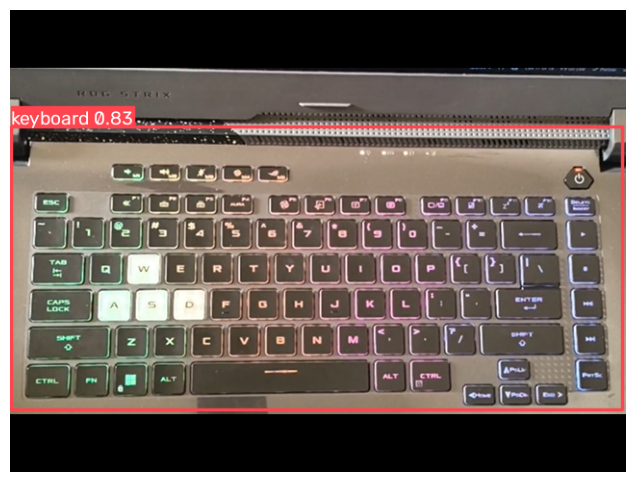

In [18]:
# Perform object detection
results = model(frame)

# Display detected objects
for result in results:

    # Get detected class names
    for box in result.boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])

        print("Object:", model.names[class_id])
        print("Confidence:", round(confidence * 100, 2), "%")

# Display detected image with bounding boxes
detected_image = results[0].plot()

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(detected_image, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

In [19]:
# Real-Time Object Detection Using YOLO

cap = cv2.VideoCapture(0)

try:
    while cap.isOpened():
        ret, frame = cap.read()

        if not ret:
            print("Unable to access webcam")
            break

        # Detect objects without printing details for every frame
        results = model(frame, verbose=False)

        # Draw bounding boxes
        detected_frame = results[0].plot()

        cv2.imshow("YOLO Object Detection", detected_frame)

        # Press q to stop
        if cv2.waitKey(1) & 0xFF == ord('q'):
            break

finally:
    cap.release()
    cv2.destroyAllWindows()

print("Object detection stopped.")


Object detection stopped.
